In [1]:
import os, time, random, itertools, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import resnet18, mobilenet_v2, efficientnet_b0
from sklearn.metrics import precision_score, recall_score, confusion_matrix
from clearml import Task, OutputModel

PROJECT = "TP1-Benchmark-MLOps-0"
config = {"seed": 42, "batch_size": 128, "num_workers": 2,
          "lr": 1e-3, "epochs": 10, "weight_decay": 1e-4}
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
train_tf = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomCrop(32, padding=4),
                               transforms.ToTensor(), transforms.Normalize(mean, std)])
test_tf  = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
train_ds = datasets.CIFAR10("./data", train=True,  transform=train_tf)
test_ds  = datasets.CIFAR10("./data", train=False, transform=test_tf)
classes  = train_ds.classes
print("Device :", device, "| config :", config)

Device : mps | config : {'seed': 42, 'batch_size': 128, 'num_workers': 2, 'lr': 0.001, 'epochs': 10, 'weight_decay': 0.0001}


In [3]:
@torch.no_grad()
def predire(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

def benchmark(nom, construire_modele):
    set_seed(config["seed"])
    # 1) Une Task ClearML par modèle
    task = Task.init(project_name=PROJECT, task_name=f"TP1-Benchmark-{nom}", reuse_last_task_id=False)
    task.connect(config)
    logger = task.get_logger()

    g = torch.Generator().manual_seed(config["seed"])
    train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True,
                              num_workers=config["num_workers"], generator=g)
    test_loader  = DataLoader(test_ds, batch_size=config["batch_size"], shuffle=False,
                              num_workers=config["num_workers"])

    # 2) Le modèle, la loss, l'optimiseur
    model = construire_modele().to(device)
    n_params = sum(p.numel() for p in model.parameters())
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    os.makedirs(f"checkpoints_{nom}", exist_ok=True)
    best_acc, best_path = 0.0, f"best_{nom}.pt"
    print(f"\n===== {nom} : {n_params:,} paramètres =====")

    # 3) Entraînement : même boucle qu'à l'étape 4
    for ep in range(config["epochs"]):
        model.train(); run_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(); out = model(x); loss = criterion(out, y)
            loss.backward(); optimizer.step()
            run_loss += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
        tl, ta = run_loss / total, correct / total

        model.eval(); run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device); out = model(x)
                run_loss += criterion(out, y).item() * x.size(0)
                correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
        vl, va = run_loss / total, correct / total

        for titre, serie, val in [("loss","train",tl), ("accuracy","train",ta), ("loss","val",vl), ("accuracy","val",va)]:
            logger.report_scalar(titre, serie, val, ep)
        print(f"{nom} ép {ep+1:2d}/{config['epochs']} | train loss {tl:.3f} acc {ta:.1%} | val loss {vl:.3f} acc {va:.1%}")

        ckpt = f"checkpoints_{nom}/epoch_{ep:03d}.pt"
        torch.save(model.state_dict(), ckpt)
        task.upload_artifact(name=f"checkpoint_epoch_{ep:03d}", artifact_object=ckpt)
        if va > best_acc:
            best_acc = va; torch.save(model.state_dict(), best_path)

    # 4) Évaluation finale sur le MEILLEUR checkpoint
    model.load_state_dict(torch.load(best_path, map_location=device))
    y_true, y_pred = predire(model, test_loader)
    acc  = (y_true == y_pred).mean()
    prec = precision_score(y_true, y_pred, average="macro")
    rec  = recall_score(y_true, y_pred, average="macro")

    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(6, 6)); ax.imshow(cm, cmap=plt.cm.Blues)
    ax.set(xticks=range(10), yticks=range(10), xticklabels=classes, yticklabels=classes,
           xlabel="Predicted", ylabel="True", title=f"Confusion Matrix - {nom}")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i, j in itertools.product(range(10), range(10)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); logger.report_matplotlib_figure("confusion_matrix", "val", fig, 0); plt.show(); plt.close(fig)

    # 5) Taille et vitesse d'inférence (CPU, 1 image)
    taille_mb = os.path.getsize(best_path) / 1024**2
    m_cpu = construire_modele(); m_cpu.load_state_dict(torch.load(best_path, map_location="cpu")); m_cpu.eval()
    x1 = torch.randn(1, 3, 32, 32)
    with torch.no_grad():
        for _ in range(20): m_cpu(x1)                      # échauffement
        t0 = time.perf_counter()
        for _ in range(200): m_cpu(x1)
    ms = (time.perf_counter() - t0) / 200 * 1000

    for k, v in {"accuracy": acc, "precision_macro": prec, "recall_macro": rec, "n_params": n_params,
                 "taille_MB": taille_mb, "inference_ms_cpu_batch1": ms}.items():
        logger.report_single_value(k, float(v))

    # 6) Model Registry
    task.upload_artifact("best_checkpoint", artifact_object=best_path)
    om = OutputModel(task=task, name=f"{nom.lower()}_cifar10_benchmark"); om.update_weights(best_path); om.publish()

    url = task.get_output_log_web_page()
    task.close()
    return {"Modèle": nom, "Accuracy %": round(100*acc, 2), "Précision %": round(100*prec, 2),
            "Rappel %": round(100*rec, 2), "Nb paramètres": n_params, "Poids (MB)": round(taille_mb, 2),
            "Inférence (ms/img)": round(ms, 2), "Lien ClearML": url}

ClearML Task: created new task id=0583002bac90403883a6f7f0d2543c65
ClearML results page: https://app.clear.ml/projects/a04fcf8a75354beaa77ed7e1a982bc35/tasks/0583002bac90403883a6f7f0d2543c65/output/log
2026-10-11 10:50:41,615 - clearml.resource_monitor - WARNING - Could not fetch GPU stats: NVML Shared Library Not Found
ClearML Monitor: GPU monitoring failed getting GPU reading, switching off GPU monitoring

===== ResNet18 : 11,181,642 paramètres =====
ResNet18 ép  1/10 | train loss 1.560 acc 42.7% | val loss 1.244 acc 54.1%


███████████████████████████████ 100% | 42.73/42.73 MB [00:23<00:00,  1.80MB/s]: 


ResNet18 ép  2/10 | train loss 1.187 acc 57.5% | val loss 1.129 acc 60.4%


███████████████████████████████ 100% | 42.73/42.73 MB [00:05<00:00,  7.32MB/s]: 


ResNet18 ép  3/10 | train loss 1.021 acc 63.8% | val loss 0.934 acc 67.6%


...

███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.44MB/s]: 


ResNet18 ép  9/10 | train loss 0.678 acc 76.5% | val loss 0.725 acc 74.9%


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.32MB/s]: 


ResNet18 ép 10/10 | train loss 0.642 acc 77.7% | val loss 0.711 acc 75.0%


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.53MB/s]: 


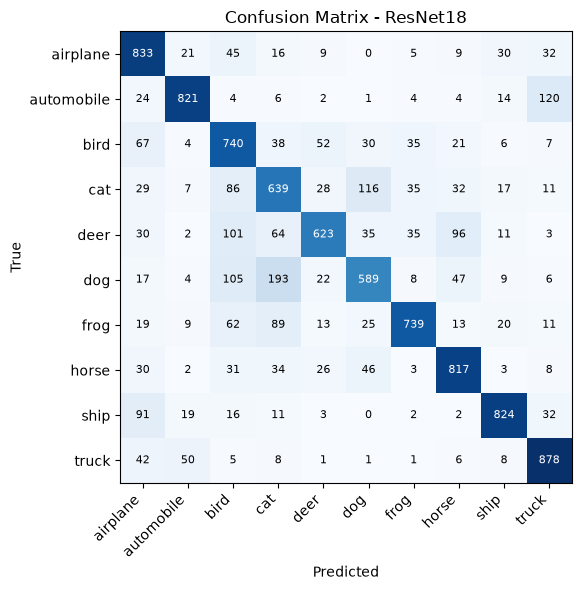

2026-10-11 11:07:43,166 - clearml.model - WARNING - Connecting multiple input models with the same name: `best_ResNet18`. This might result in the wrong model being used when executing remotely


███████████████████████████████ 100% | 42.73/42.73 MB [00:04<00:00, 10.43MB/s]: 


ClearML Task: created new task id=1a6f85056eb14aadadb00f8b6bcb8c55


Could not fetch GPU stats: NVML Shared Library Not Found


ClearML results page: https://app.clear.ml/projects/a04fcf8a75354beaa77ed7e1a982bc35/tasks/1a6f85056eb14aadadb00f8b6bcb8c55/output/log
ClearML Monitor: GPU monitoring failed getting GPU reading, switching off GPU monitoring

===== MobileNetV2 : 2,236,682 paramètres =====
MobileNetV2 ép  1/10 | train loss 2.028 acc 23.2% | val loss 1.743 acc 33.4%


...

█████████████████████████████████ 100% | 8.76/8.76 MB [00:00<00:00,  8.76MB/s]: 


MobileNetV2 ép  9/10 | train loss 1.082 acc 62.0% | val loss 1.025 acc 64.1%


█████████████████████████████████ 100% | 8.76/8.76 MB [00:00<00:00, 11.88MB/s]: 


MobileNetV2 ép 10/10 | train loss 1.031 acc 63.5% | val loss 0.987 acc 64.6%


█████████████████████████████████ 100% | 8.76/8.76 MB [00:00<00:00, 11.26MB/s]: 


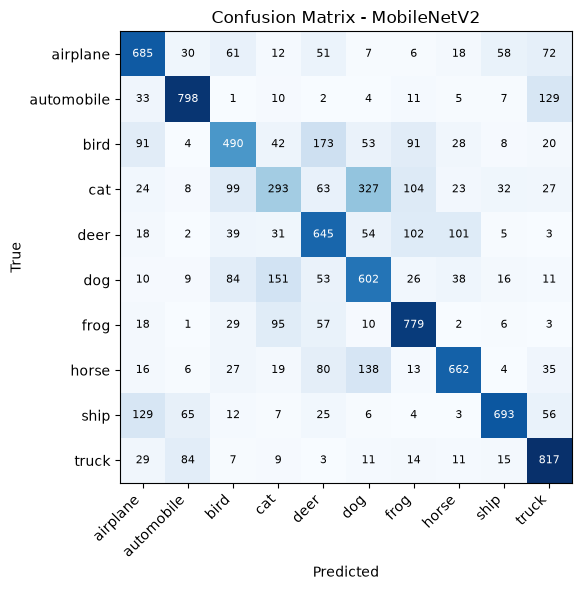

Connecting multiple input models with the same name: `best_MobileNetV2`. This might result in the wrong model being used when executing remotely
█████████████████████████████████ 100% | 8.76/8.76 MB [00:00<00:00, 11.04MB/s]: 
█████████████████████████████████ 100% | 8.76/8.76 MB [00:20<00:00,  2.35s/MB]: 


ClearML Task: created new task id=d1cb43df4e284f2483c966abdbd50e28


Could not fetch GPU stats: NVML Shared Library Not Found


ClearML results page: https://app.clear.ml/projects/a04fcf8a75354beaa77ed7e1a982bc35/tasks/d1cb43df4e284f2483c966abdbd50e28/output/log
ClearML Monitor: GPU monitoring failed getting GPU reading, switching off GPU monitoring

===== EfficientNetB0 : 4,020,358 paramètres =====
EfficientNetB0 ép  1/10 | train loss 2.855 acc 16.6% | val loss 2.009 acc 24.5%


███████████████████████████████ 100% | 15.62/15.62 MB [00:01<00:00, 10.59MB/s]: 


...

███████████████████████████████ 100% | 15.62/15.62 MB [00:01<00:00, 10.56MB/s]: 


EfficientNetB0 ép  9/10 | train loss 1.859 acc 38.7% | val loss 1.711 acc 39.4%


███████████████████████████████ 100% | 15.62/15.62 MB [00:01<00:00, 10.44MB/s]: 


EfficientNetB0 ép 10/10 | train loss 1.890 acc 38.8% | val loss 1.485 acc 45.7%


███████████████████████████████ 100% | 15.62/15.62 MB [00:01<00:00,  8.25MB/s]: 
███████████████████████████████ 100% | 15.62/15.62 MB [20:20<00:00, 78.11s/MB]: 


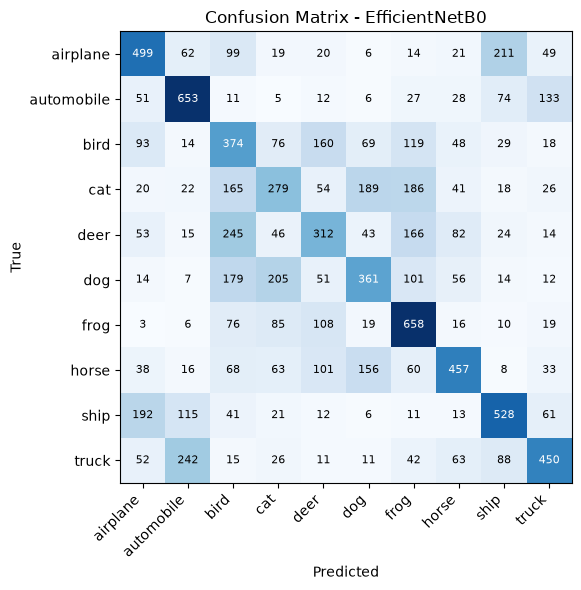

Connecting multiple input models with the same name: `best_EfficientNetB0`. This might result in the wrong model being used when executing remotely
███████████████████████████████ 100% | 15.62/15.62 MB [00:01<00:00, 10.56MB/s]: 


In [4]:
modeles = [("ResNet18",       lambda: resnet18(num_classes=10)),
           ("MobileNetV2",    lambda: mobilenet_v2(num_classes=10)),
           ("EfficientNetB0", lambda: efficientnet_b0(num_classes=10))]
resultats = [benchmark(nom, f) for nom, f in modeles]

In [5]:
for r in resultats:
    print(r)

{'Modèle': 'ResNet18', 'Accuracy %': np.float64(75.03), 'Précision %': 75.79, 'Rappel %': 75.03, 'Nb paramètres': 11181642, 'Poids (MB)': 42.73, 'Inférence (ms/img)': 2.54, 'Lien ClearML': 'https://app.clear.ml/projects/a04fcf8a75354beaa77ed7e1a982bc35/tasks/0583002bac90403883a6f7f0d2543c65/output/log'}
{'Modèle': 'MobileNetV2', 'Accuracy %': np.float64(64.64), 'Précision %': 64.53, 'Rappel %': 64.64, 'Nb paramètres': 2236682, 'Poids (MB)': 8.76, 'Inférence (ms/img)': 39.03, 'Lien ClearML': 'https://app.clear.ml/projects/a04fcf8a75354beaa77ed7e1a982bc35/tasks/1a6f85056eb14aadadb00f8b6bcb8c55/output/log'}
{'Modèle': 'EfficientNetB0', 'Accuracy %': np.float64(45.71), 'Précision %': 45.86, 'Rappel %': 45.71, 'Nb paramètres': 4020358, 'Poids (MB)': 15.62, 'Inférence (ms/img)': 229.2, 'Lien ClearML': 'https://app.clear.ml/projects/a04fcf8a75354beaa77ed7e1a982bc35/tasks/d1cb43df4e284f2483c966abdbd50e28/output/log'}
